## Model 3: avoided crossings of the Z1 hyperfine levels, and DBQA across them

At weak fields the Zeeman and hyperfine energies of Z1 are comparable and the 16 hyperfine levels go through many avoided crossings. This notebook
1. locates the avoided crossings along the three crystal axes D1, D2 and b (0–200 mT), in the crystal-field model (Model 3) and in the measured spin Hamiltonian used by Matsuura et al. (S.-J. Wang et al.'s tensors), and compares their fields and gaps;
2. checks that Model 3 has no symmetry sectors;
3. runs two-stage DBQA across two avoided crossings of the crystal-field model and reports, for the two levels of each crossing, the individual and pair-subspace fidelities and the gap error, the metrics proposed in `RESULTS_Model_1.md` for close pairs.

Matsuura et al. show avoided crossings only in figures (site 1, field along D1), so the comparison here is between the two Hamiltonians, both computed by us. The notebook takes about 45 minutes.

In [1]:
import os

os.environ["OPENBLAS_NUM_THREADS"] = "1"

import logging
import multiprocessing as mp
import pickle
import time
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import connected_components

from qibo import set_backend
from qibo.config import log

from pycf.import_sljm import ImportSLJM

from qibo_dbqa.utils import generate_Z_operators
from qibo_dbqa.utils_crystal_field import *

os.environ.setdefault("PYCF_ROOT", os.path.abspath("../../../pycf"))
set_backend("numpy")
log.setLevel(logging.ERROR)
os.makedirs("pdfs_figures", exist_ok=True)
os.makedirs("simulation_results", exist_ok=True)

model = hyperfine_field_model(ImportSLJM(pycf_matel_path("erhfs", "eryso")), er_yso_pycf_coeff(hyperfine=ER_YSO_SITE2_HYPERFINE_JOBBITT2021))
h0, operators = model["h0"], field_operators(model)
W = ER_YSO_SITE2_WANG_SPIN_HAMILTONIAN
sh0, sh_operators = spin_hamiltonian_model(W["A"], W["Q"], W["g"])

[Qibo 0.2.14|INFO|2026-10-17 09:09:55]: Using numpy backend on /CPU:0


#### Symmetry sectors

Model 2's Hamiltonian splits into four sectors that DB-DOI cannot leave (`RESULTS_Model_2.md` §5.3). The C$_1$ crystal field together with the hyperfine and Zeeman terms couples every state of Model 3:

In [2]:
for label, field in (("B = 0", np.zeros(3)), ("B = B* of Example 9", np.array([-0.1482, 0.0083, 0.0208]))):
    matrix = linear_field_hamiltonian(h0, operators, field)
    n_components, _ = connected_components(np.abs(matrix) > 1e-12, directed=False)
    print(f"{label}: {n_components} connected component(s) among 240 states; {np.mean(np.abs(matrix) > 1e-12):.1%} of the matrix elements are non-zero")

B = 0: 1 connected component(s) among 240 states; 10.8% of the matrix elements are non-zero
B = B* of Example 9: 1 connected component(s) among 240 states; 11.5% of the matrix elements are non-zero


#### Avoided crossings along D1, D2 and b

`avoided_crossings` finds the interior local minima of every gap $E_{k+1}-E_k$ of the 16 Z1 levels on a grid of 801 fields in [0, 200] mT and refines each one. Crossings in the two models are matched by level pair and field.

axis  levels  field CF  field SH  gap CF (MHz)  gap SH (MHz)
D1    (7, 8)    3.87mT    3.83mT        10.692        87.089
D1   (9, 10)    3.80mT    3.85mT         0.253        48.278
D1   (11, 12)    3.73mT    3.86mT         0.002         9.331
D1   (13, 14)    3.67mT    3.86mT         0.000         0.673
D1    (5, 6)    3.95mT    3.95mT         1.122        21.686
D1    (3, 4)    4.01mT    4.06mT         0.020         5.290
D1    (1, 2)    4.08mT    4.24mT         0.000         0.402
D1   (12, 13)    7.40mT    7.71mT         0.004         7.085
D1   (10, 11)    7.54mT    7.73mT         0.997        76.905
D1    (8, 9)    7.68mT    7.83mT       133.564       341.449
D1    (6, 7)    7.87mT    7.87mT       508.657       177.583
D1    (4, 5)    7.96mT    8.01mT         9.078        51.241
D1    (2, 3)    8.09mT    8.30mT         0.054         4.566
D1   (11, 12)   11.20mT   11.58mT         0.004        18.621
D1    (7, 8)   11.60mT   11.59mT        32.058       244.491
D1   (9, 10)   11.4

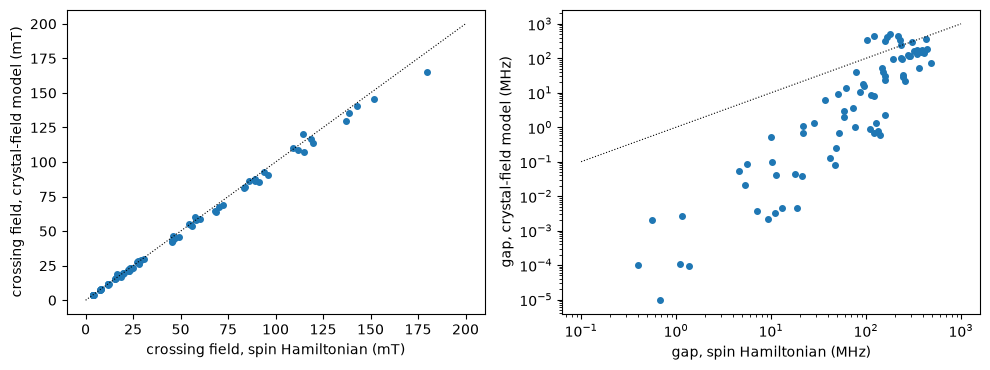

In [3]:
grid = np.linspace(0, 0.2, 801)
crossings = {}
for axis, direction in zip(("D1", "D2", "b"), np.eye(3)):
    crossings[axis] = dict(
        cf=[dict(c, gap=c["gap"] * CM_TO_MHZ) for c in avoided_crossings(h0, operators, direction, grid, 16)],
        sh=avoided_crossings(sh0, sh_operators, direction, grid, 16),
    )

print(f"{'axis':4s} {'levels':>7s} {'field CF':>9s} {'field SH':>9s} {'gap CF (MHz)':>13s} {'gap SH (MHz)':>13s}")
matches = []
for axis, c in crossings.items():
    for x in c["sh"]:
        same = [y for y in c["cf"] if y["levels"] == x["levels"]]
        if not same:
            continue
        y = min(same, key=lambda y: abs(y["field"] - x["field"]))
        if abs(y["field"] - x["field"]) > 0.25 * x["field"]:
            continue
        matches.append(dict(axis=axis, levels=x["levels"], field_sh=x["field"], field_cf=y["field"], gap_sh=x["gap"], gap_cf=y["gap"]))
        print(f"{axis:4s} {str(x['levels']):>7s} {y['field'] * 1e3:7.2f}mT {x['field'] * 1e3:7.2f}mT {y['gap']:13.3f} {x['gap']:13.3f}")
field_ratio = np.array([m["field_cf"] / m["field_sh"] for m in matches])
gap_cf = np.array([m["gap_cf"] for m in matches]); gap_sh = np.array([m["gap_sh"] for m in matches])
print(f"\n{len(matches)} matched crossings (CF found {sum(len(c['cf']) for c in crossings.values())}, SH {sum(len(c['sh']) for c in crossings.values())})")
print(f"field CF / field SH: median {np.median(field_ratio):.3f}, range {field_ratio.min():.3f}-{field_ratio.max():.3f}")
print(f"gap CF / gap SH: median {np.median(gap_cf / gap_sh):.2e}; {np.sum(gap_cf < 0.01)} of {len(matches)} CF gaps below 0.01 MHz, against {np.sum(gap_sh < 0.01)} SH gaps")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot([m["field_sh"] * 1e3 for m in matches], [m["field_cf"] * 1e3 for m in matches], "o", ms=4)
axes[0].plot([0, 200], [0, 200], "k:", lw=0.8)
axes[0].set_xlabel("crossing field, spin Hamiltonian (mT)"); axes[0].set_ylabel("crossing field, crystal-field model (mT)")
axes[1].loglog(gap_sh, np.maximum(gap_cf, 1e-6), "o", ms=4)
axes[1].plot([1e-1, 1e3], [1e-1, 1e3], "k:", lw=0.8)
axes[1].set_xlabel("gap, spin Hamiltonian (MHz)"); axes[1].set_ylabel("gap, crystal-field model (MHz)")
plt.tight_layout()
plt.savefig("pdfs_figures/Er_YSO_avoided_crossings.pdf")
plt.show()

#### Two crossings for DBQA

Rule, fixed before the runs: along D1, the narrowest crossing of the crystal-field model with a gap of at least 1 MHz ("narrow"), and the crossing whose gap is closest to 100 MHz ("wide"). Each is swept over 11 fields spanning the interval in which the exact gap is below three times its minimum.

In [4]:
d1 = np.array([1.0, 0.0, 0.0])
candidates = crossings["D1"]["cf"]
narrow = min([c for c in candidates if c["gap"] >= 1.0], key=lambda c: c["gap"])
wide = min(candidates, key=lambda c: abs(np.log(c["gap"] / 100.0)))


def gap_along(b, k):
    e = np.linalg.eigvalsh(linear_field_hamiltonian(h0, operators, b * d1))
    return (e[k + 1] - e[k]) * CM_TO_MHZ


sweeps = {}
for name, c in (("narrow", narrow), ("wide", wide)):
    k = c["levels"][0]
    fine = np.linspace(c["field"] * 0.9, c["field"] * 1.1, 2001)
    gaps = np.array([gap_along(b, k) for b in fine])
    inside = fine[gaps < 3 * c["gap"]]
    sweeps[name] = dict(levels=c["levels"], field=c["field"], gap=c["gap"], magnitudes=np.linspace(inside.min(), inside.max(), 11))
    print(f"{name}: levels {c['levels']}, minimum gap {c['gap']:.3f} MHz at {c['field'] * 1e3:.4f} mT; sweep {inside.min() * 1e3:.4f}-{inside.max() * 1e3:.4f} mT")

narrow: levels (5, 6), minimum gap 1.122 MHz at 3.9489 mT; sweep 3.9307-3.9670 mT


wide: levels (8, 9), minimum gap 93.555 MHz at 23.0358 mT; sweep 21.7204-24.3419 mT


#### DBQA across the crossings

- **Stage A** (8 qubits, units of 5 000 cm$^{-1}$, group commutator, 100 durations in $[10^{-3},10^2]$): cold at the first field of each sweep, then warm-started from the previous field's rotation, until $1-F<10^{-9}$ for Z1. `Example_10` shows that this leaves transition-frequency errors of about $2\times10^{-4}$ MHz, far below both gaps.
- **Stage B** (4 qubits): 100 iterations on the captured block, normalised to unit spectral norm, with 140 durations in $[10^{-3},10^4]$. In these units the narrow gap is about $10^{-4}$, so durations up to $10^4$ are needed. Group commutator at every field, cold and warm-started; canonical and Pauli-Z at the centre of each sweep.
- **Metrics** for the two levels $k, k+1$ of the crossing, from the sorted DBQA diagonal: individual infidelities, the pair-subspace infidelity, and the gap error; the pair counts as resolved once the gap error stays below 10 % of the exact gap (`RESULTS_Model_1.md` §5).

The two sweeps run in parallel processes.

In [5]:
STARK = [list(range(16 * k, 16 * k + 16)) for k in range(16)]
SPACE_A = np.logspace(-3, 2, 100)
SPACES_B = {"group commutator": np.logspace(-3, 4, 140), "canonical": np.logspace(-3, 4, 140), "Pauli-Z": np.logspace(-3, 4, 50)}
Z_OPS = [np.real(op) for op in generate_Z_operators(4).values()]
NSTEPS_B = 100


def embedded(b):
    padded, _, _ = embed_in_qubits(linear_field_hamiltonian(h0, operators, b * d1))
    return (padded - np.trace(padded).real / 256 * np.eye(256)) / 5000.0


def stage_b(block, exact, pair, method, rotation=None):
    shifted = block - np.trace(block).real / 16 * np.eye(16)
    unit = np.max(np.abs(np.linalg.eigvalsh(shifted)))
    matrix = shifted / unit if rotation is None else rotation.conj().T @ (shifted / unit) @ rotation
    exact_block = np.linalg.eigvalsh(matrix)
    singles = [[k] for k in range(16)]
    merged = [[k] for k in range(16) if k not in pair] + [list(pair)]
    run = run_dbqa_history(matrix, method, dict(singles=singles, merged=merged), NSTEPS_B, SPACES_B[method],
                           d_list=Z_OPS if method == "Pauli-Z" else None, checkpoints=tuple(range(NSTEPS_B + 1)), track_unitary=True)
    i, j = pair
    gap_exact = (exact[j] - exact[i]) * CM_TO_MHZ
    out = dict(individual=[], pair=[], gap_error=[], transition_error=[])
    reference = (exact - exact[0]) * CM_TO_MHZ
    for k in range(NSTEPS_B + 1):
        r = run["history"][k]
        out["individual"].append(1 - r["singles"]["level_fidelity"][[i, j]])
        out["pair"].append(1 - r["merged"]["level_fidelity"][-1])
        d = np.sort(np.real(np.diag(run["checkpoints"][k]))) * unit
        estimate = (d - d[0]) * CM_TO_MHZ
        out["gap_error"].append(abs((estimate[j] - estimate[i]) - gap_exact))
        out["transition_error"].append(np.max(np.abs(estimate - reference)))
    out = {key: np.array(v) for key, v in out.items()}
    out.update(gap_exact=gap_exact, resolved_at=next((k for k in range(NSTEPS_B + 1) if np.all(out["gap_error"][k:] < 0.1 * gap_exact)), None),
               steps=run["steps"])
    return out, run["unitary"]


def sweep_crossing(name):
    sweep = sweeps[name]
    pair = sweep["levels"]
    results = []
    u_prev, v_prev = None, None
    for n, b in enumerate(sweep["magnitudes"]):
        start = time.time()
        exact = np.linalg.eigvalsh(linear_field_hamiltonian(h0, operators, b * d1))[:16]
        h = embedded(b)
        h_start = h if u_prev is None else u_prev.conj().T @ h @ u_prev
        run_a = run_dbqa_history(h_start, "group commutator", dict(stark=STARK), 250, SPACE_A, capture=("stark", 0, (1e-9,)),
                                 track_unitary=True, stop_when_captured=True)
        k_a, matrix_a = run_a["captured"][1e-9]
        u_prev = run_a["captured_unitary"][1e-9] if u_prev is None else u_prev @ run_a["captured_unitary"][1e-9]
        index = np.sort(np.argsort(np.real(np.diag(matrix_a)))[:16])
        block = matrix_a[np.ix_(index, index)] * 5000.0
        cold_b, _ = stage_b(block, exact, pair, "group commutator")
        warm_b, v = stage_b(block, exact, pair, "group commutator", rotation=v_prev)
        v_prev = v if v_prev is None else v_prev @ v
        entry = dict(field=b, stage_a_iterations=k_a, cold_start_a=(n == 0), cold=cold_b, warm=warm_b)
        if n == len(sweep["magnitudes"]) // 2:
            entry["others"] = {method: stage_b(block, exact, pair, method)[0] for method in ("canonical", "Pauli-Z")}
        results.append(entry)
        print(f"{name} {b * 1e3:.4f} mT: stage A {k_a} its ({'cold' if n == 0 else 'warm'}); gap {cold_b['gap_exact']:.3f} MHz; "
              f"stage B resolved at {cold_b['resolved_at']} (cold) / {warm_b['resolved_at']} (warm); final gap error {cold_b['gap_error'][-1]:.1e} MHz; {time.time() - start:.0f} s", flush=True)
    return results


start = time.time()
with ProcessPoolExecutor(max_workers=2, mp_context=mp.get_context("fork")) as pool:
    runs = dict(zip(("narrow", "wide"), pool.map(sweep_crossing, ("narrow", "wide"))))
print(f"{(time.time() - start) / 60:.0f} min")

/home/aarush_das_bansiwal/micromamba/envs/dbqa-cf/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/aarush_das_bansiwal/micromamba/envs/dbqa-cf/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


wide 21.7204 mT: stage A 106 its (cold); gap 280.323 MHz; stage B resolved at 35 (cold) / 35 (warm); final gap error 4.3e-04 MHz; 152 s

wide 21.9826 mT: stage A 0 its (warm); gap 231.569 MHz; stage B resolved at 38 (cold) / 0 (warm); final gap error 5.1e-04 MHz; 1 s

wide 22.2447 mT: stage A 0 its (warm); gap 184.712 MHz; stage B resolved at 34 (cold) / 0 (warm); final gap error 5.6e-04 MHz; 1 s

...

narrow 3.9634 mT: stage A 0 its (warm); gap 2.771 MHz; stage B resolved at 33 (cold) / 0 (warm); final gap error 3.8e-04 MHz; 1 s

wide 24.0798 mT: stage A 1 its (warm); gap 230.970 MHz; stage B resolved at 22 (cold) / 0 (warm); final gap error 2.8e-04 MHz; 2 s

narrow 3.9670 mT: stage A 0 its (warm); gap 3.360 MHz; stage B resolved at 62 (cold) / 0 (warm); final gap error 3.9e-04 MHz; 1 s

wide 24.3419 mT: stage A 1 its (warm); gap 280.362 MHz; stage B resolved at 18 (cold) / 0 (warm); final gap error 1.8e-04 MHz; 2 s

3 min



narrow crossing, levels (5, 6), gap 1.122 MHz at 3.9489 mT
   stage A iterations: [113, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0] (first cold, then warm)
   stage B (group commutator) resolved at, cold: [59, 49, 60, 50, 59, 64, 64, 64, 60, 33, 62]
   stage B (group commutator) resolved at, warm: [59, 0, 0, 0, 0, 2, 1, 0, 0, 0, 0]
   centre, group commutator: final individual 1-F [2.e-07 2.e-07], pair 1-F 1.0e-14, gap error 6.15e-05 MHz (0.0% of the gap), max Z1 transition error 5.42e-04 MHz, resolved at 64
   centre, canonical       : final individual 1-F [0.3 0.2], pair 1-F 7.2e-03, gap error 1.01e+01 MHz (900.2% of the gap), max Z1 transition error 3.37e+01 MHz, resolved at None
   centre, Pauli-Z         : final individual 1-F [0.3 0.3], pair 1-F 1.1e-04, gap error 6.23e-01 MHz (55.6% of the gap), max Z1 transition error 1.13e+01 MHz, resolved at None

wide crossing, levels (8, 9), gap 93.555 MHz at 23.0358 mT
   stage A iterations: [106, 0, 0, 0, 2, 0, 1, 0, 4, 1, 1] (first cold, then warm)
 

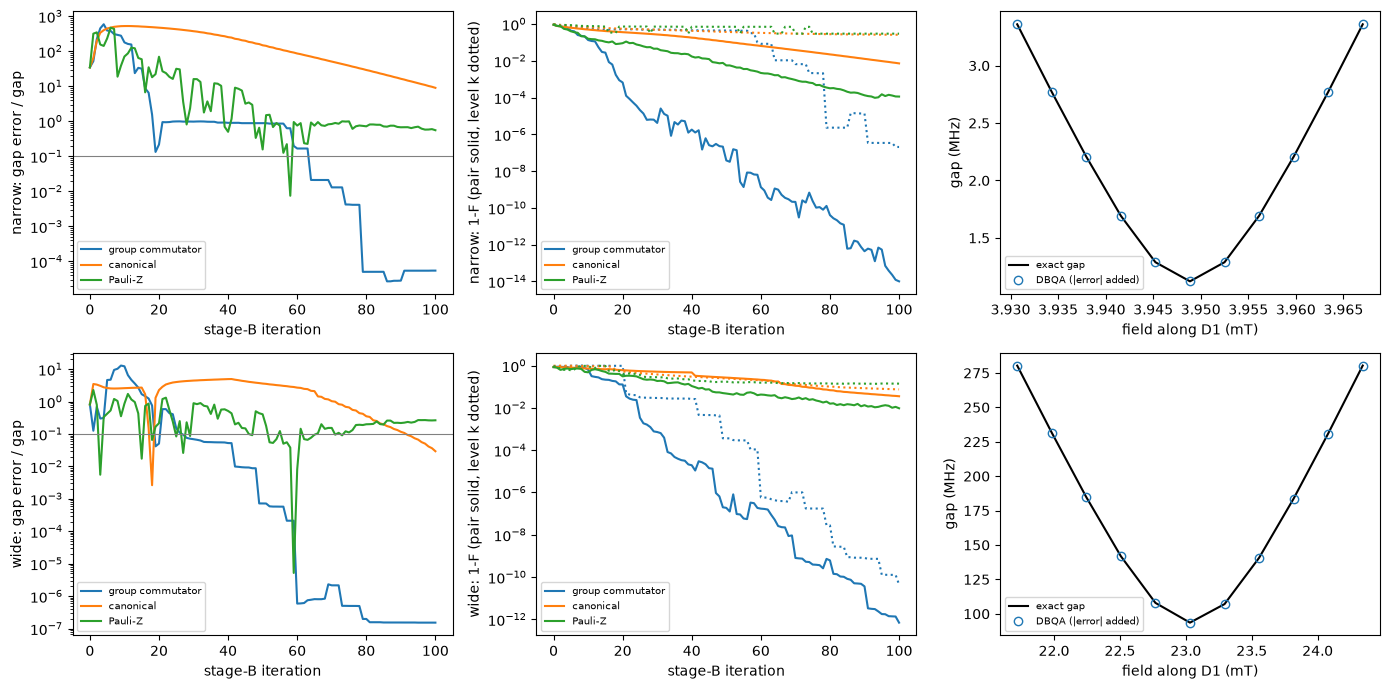

In [6]:
for name, results in runs.items():
    sweep = sweeps[name]
    mid = results[len(results) // 2]
    print(f"\n{name} crossing, levels {sweep['levels']}, gap {sweep['gap']:.3f} MHz at {sweep['field'] * 1e3:.4f} mT")
    print(f"   stage A iterations: {[r['stage_a_iterations'] for r in results]} (first cold, then warm)")
    print(f"   stage B (group commutator) resolved at, cold: {[r['cold']['resolved_at'] for r in results]}")
    print(f"   stage B (group commutator) resolved at, warm: {[r['warm']['resolved_at'] for r in results]}")
    for label, r in [("group commutator", mid["cold"])] + list(mid["others"].items()):
        print(f"   centre, {label:16s}: final individual 1-F {np.array2string(r['individual'][-1], precision=1)}, pair 1-F {r['pair'][-1]:.1e}, "
              f"gap error {r['gap_error'][-1]:.2e} MHz ({r['gap_error'][-1] / r['gap_exact']:.1%} of the gap), max Z1 transition error {r['transition_error'][-1]:.2e} MHz, resolved at {r['resolved_at']}")

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for row, (name, results) in enumerate(runs.items()):
    mid = results[len(results) // 2]
    for label, r in [("group commutator", mid["cold"])] + list(mid["others"].items()):
        axes[row, 0].semilogy(r["gap_error"] / r["gap_exact"], label=label)
        axes[row, 1].semilogy(r["pair"], label=label)
        axes[row, 1].semilogy(r["individual"][:, 0], ls=":", color=axes[row, 1].lines[-1].get_color())
    axes[row, 0].axhline(0.1, color="gray", lw=0.8)
    axes[row, 0].set_ylabel(f"{name}: gap error / gap"); axes[row, 1].set_ylabel(f"{name}: 1-F (pair solid, level k dotted)")
    axes[row, 2].plot([r["field"] * 1e3 for r in results], [r["cold"]["gap_exact"] for r in results], "k-", label="exact gap")
    axes[row, 2].plot([r["field"] * 1e3 for r in results], [r["cold"]["gap_exact"] + r["cold"]["gap_error"][-1] for r in results], "o", mfc="none", label="DBQA (|error| added)")
    axes[row, 2].set_xlabel("field along D1 (mT)"); axes[row, 2].set_ylabel("gap (MHz)")
    for ax in axes[row, :2]:
        ax.set_xlabel("stage-B iteration"); ax.legend(fontsize=7)
    axes[row, 2].legend(fontsize=7)
plt.tight_layout()
plt.savefig("pdfs_figures/Er_YSO_avoided_crossing_dbqa.pdf")
plt.show()

with open("simulation_results/Er_YSO_avoided_crossings.pickle", "wb") as file:
    pickle.dump(dict(crossings=crossings, matches=matches, sweeps=sweeps, runs=runs), file)

#### Conclusions

- **No symmetry sectors** in Model 3, at zero field or at $\vec B^*$.
- **Crossing fields agree, gaps do not.** 77 avoided crossings match between the crystal-field model and the measured spin Hamiltonian, with fields within a few per cent (median ratio 0.976), set by the g and A tensors. The crystal-field gaps are typically ten times smaller, and 11 are below 0.01 MHz where the spin Hamiltonian has 0.4–19 MHz: the gaps depend on the anisotropic and quadrupole couplings, which the crystal-field fit does not reproduce.
- **DBQA resolves both crossings.** With stage A at $1-F<10^{-9}$ and stage-B durations up to $10^4$, the group commutator resolves the 1.12 MHz crossing (gap error $6\times10^{-5}$ MHz, pair infidelity $10^{-14}$) and the 93.6 MHz crossing (gap error $1.4\times10^{-5}$ MHz) at every field of the sweeps. The pair is isolated long before it is resolved internally. The canonical bracket and Pauli-Z isolate the pair but do not resolve it.
- **Warm starts** make every field after the first nearly free: 0–4 stage-A and 0–2 stage-B iterations.